# Week 2 — Data Preparation and Baseline
**Project:** Remaining Useful Life (RUL) prediction of turbofan engines — NASA C-MAPSS, subset FD002
**Team:** Thiya Papuge, Mathis Le Texier, Hugo De Benetti

Objectives of this milestone (Lab 4, Week 2):
1. Clean and preprocess the dataset.
2. Analyse features, missing values and target distribution.
3. Define training, validation and test sets — **and audit the provided train/test split**.
4. Select and implement a baseline model.
5. Evaluate initial performance with appropriate metrics (RMSE, MAE, NASA score).

All paths are relative to the `notebooks/` folder. Reusable code lives in `../src/cmapss.py`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

from src.cmapss import (SETTINGS, SENSORS, CONSTANT_SENSORS, QUANTISED_SENSORS, RUL_CAP,
                        RANDOM_STATE, load_raw, ConditionNormalizer, regression_report,
                        last_cycle, random_truncation)

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 160, 'display.max_columns', 40)

DATA_RAW = Path('../data/raw')
DATA_PROCESSED = Path('../data/processed')
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

## 1. Loading and data-quality checks

In [2]:
train = load_raw(DATA_RAW / 'train_data.csv')
test = load_raw(DATA_RAW / 'test_data.csv')
print('train', train.shape, '| test', test.shape)
train.head()

train (53759, 30) | test (33991, 30)


,unit_id,cycle,setting_1,setting_2,setting_3,T2,T24,T30,T50,P2,P15,P30,Nf,Nc,epr,Ps30,phi,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32,RUL,dataset,split,engine_uid
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,8.00,194.64,2222.65,8341.91,1.02,42.02,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071,148,FD002,train,train_001
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,5.71,138.51,2211.57,8303.96,1.02,42.20,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665,147,FD002,train,train_001
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,9.02,175.71,1915.11,8001.42,0.94,36.69,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723,146,FD002,train,train_001
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,5.71,138.46,2211.58,8303.96,1.02,41.96,130.72,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701,145,FD002,train,train_001
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,9.03,175.05,1915.10,7993.23,0.94,36.89,164.31,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286,144,FD002,train,train_001


In [3]:
def quality(df, name):
    g = df.groupby('engine_uid')
    return pd.Series({
        'rows': len(df),
        'engines': df['engine_uid'].nunique(),
        'missing values': int(df.isna().sum().sum()),
        'duplicated rows': int(df.duplicated().sum()),
        'subset(s)': ', '.join(df['dataset'].unique()),
        'first cycle always 1': bool((g['cycle'].min() == 1).all()),
        'cycles contiguous (no gap)': bool(g['cycle'].apply(lambda c: (np.diff(np.sort(c)) == 1).all()).all()),
        'RUL + cycle constant per engine': bool((g.apply(lambda x: (x['RUL'] + x['cycle']).nunique()) == 1).all()),
        'RUL at last cycle (min / max)': f"{last_cycle(df)['RUL'].min()} / {last_cycle(df)['RUL'].max()}",
        'cycles per engine (min / median / max)': f"{g.size().min()} / {int(g.size().median())} / {g.size().max()}",
    }, name=name)

pd.concat([quality(train, 'train'), quality(test, 'test')], axis=1)

,train,test
rows,53759,33991
engines,260,259
missing values,0,0
duplicated rows,0,0
subset(s),FD002,FD002
first cycle always 1,True,True
cycles contiguous (no gap),True,True
RUL + cycle constant per engine,True,True
RUL at last cycle (min / max),0 / 0,6 / 194
cycles per engine (min / median / max),128 / 199 / 378,21 / 132 / 367


In [4]:
print(train.dtypes.value_counts())
train[SETTINGS + SENSORS].describe().T.round(3)

float64    22
int64       5
str         3
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
setting_1,53759.0,23.998,14.747,0.000,10.005,25.001,41.998,42.008
setting_2,53759.0,0.572,0.310,0.000,0.251,0.700,0.840,0.842
setting_3,53759.0,94.046,14.238,60.000,100.000,100.000,100.000,100.000
T2,53759.0,472.910,26.390,445.000,445.000,462.540,491.190,518.670
T24,53759.0,579.672,37.289,535.530,549.570,555.980,607.340,644.520
T30,53759.0,1419.971,105.946,1243.730,1352.760,1369.180,1499.370,1612.880
T50,53759.0,1205.442,119.123,1023.770,1123.655,1138.890,1306.850,1439.230
P2,53759.0,8.032,3.614,3.910,3.910,7.050,10.520,14.620
P15,53759.0,11.601,5.432,5.710,5.720,9.030,15.490,21.610
P30,53759.0,282.607,146.005,136.800,139.935,194.660,394.080,555.820


**Findings.** No missing values, no duplicated rows, every engine starts at cycle 1 with no gap, and all columns are numeric
(except the `dataset`/`split` labels). No imputation or type fixing is needed. The checks that matter are structural (next section).

## 2. How was the train/test split produced? — Audit

The CSV files come from the Hugging Face mirror of **NASA C-MAPSS** (Saxena et al., 2008). The split is **not** a random split made by the
uploader: it is the **original NASA split** of FD002, which works like this:

| | Train (`train_FD002.txt`) | Test (`test_FD002.txt` + `RUL_FD002.txt`) |
|---|---|---|
| Engines | 260 simulated engines | 259 **other** simulated engines |
| Trajectory | run-to-failure: observed until the failure cycle | **cut at a random cycle** before failure |
| Label | RUL = last cycle − current cycle | only the true RUL at the cut point was published in a separate file |

The Hugging Face version merged the NASA files into one table and filled a `RUL` column for every test row as
`RUL(cycle) = RUL_at_cut + (last_cycle − cycle)`. The checks below verify each of these claims on the data.

### 2.1 Train engines run to failure, test engines are truncated

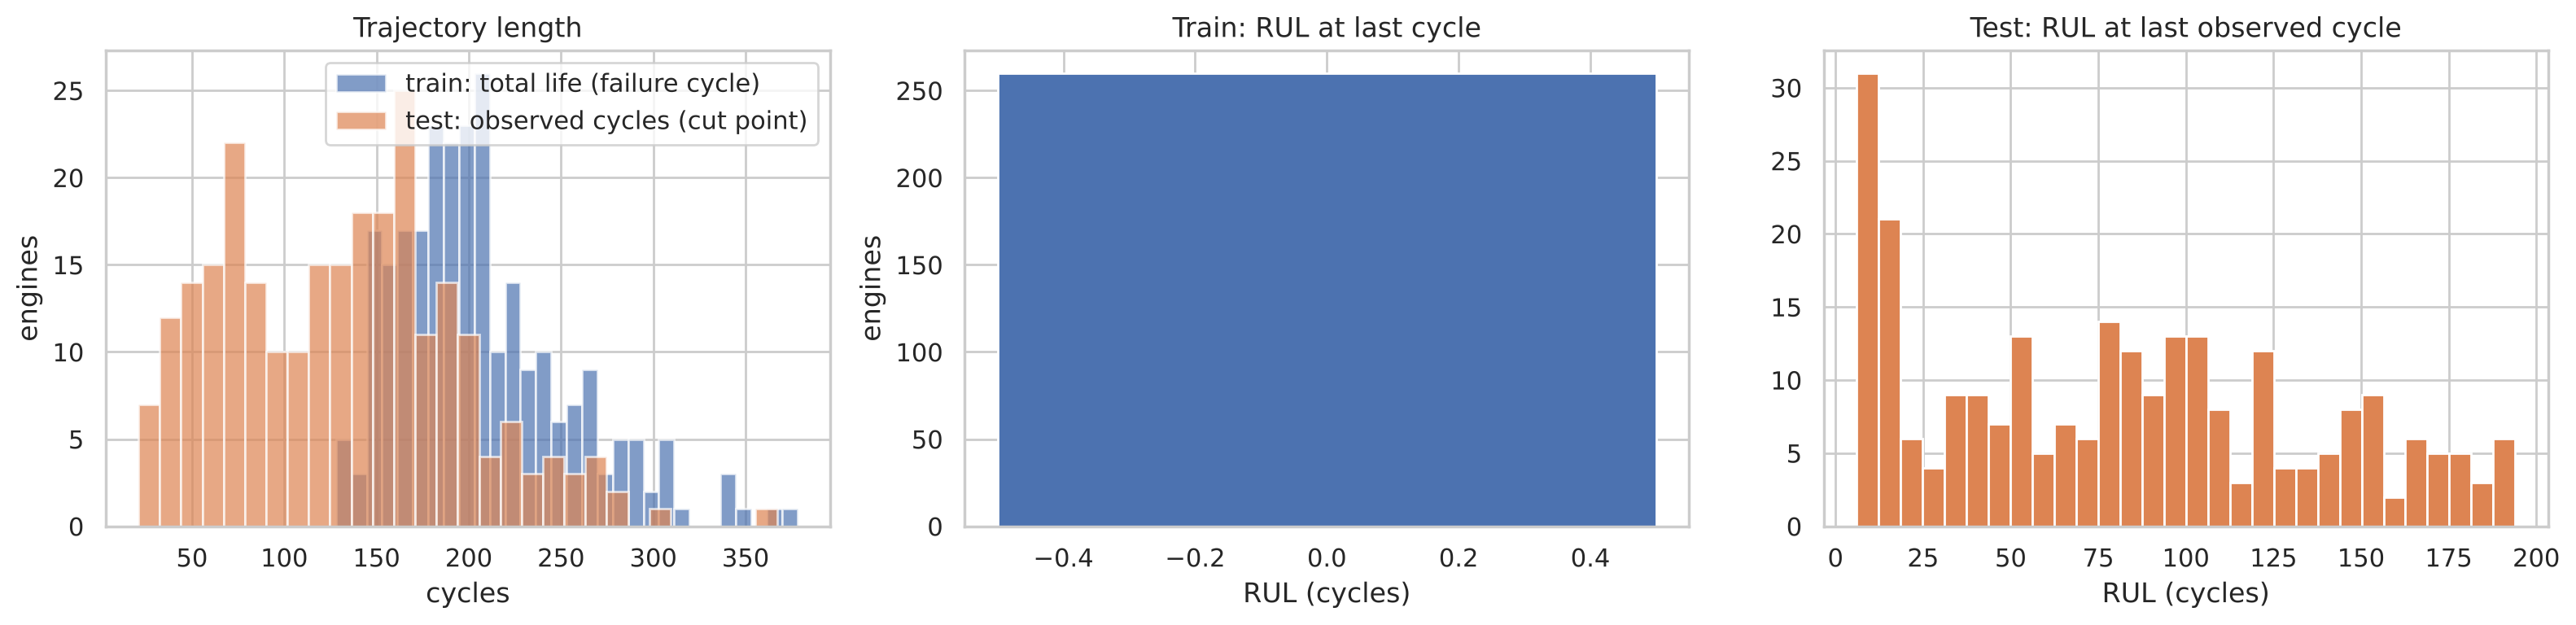

Train: RUL at last cycle is 0 for 100.0 % of engines -> run-to-failure
Test : RUL at cut point ranges 6 - 194 cycles -> truncated trajectories
Test : implied total life (cut + RUL) median = 204 vs train median life = 199


In [5]:
life_tr = train.groupby('engine_uid')['cycle'].max()
life_te = test.groupby('engine_uid')['cycle'].max()
rul_end_te = last_cycle(test).set_index('engine_uid')['RUL']

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(life_tr, bins=30, alpha=.7, label='train: total life (failure cycle)')
ax[0].hist(life_te, bins=30, alpha=.7, label='test: observed cycles (cut point)')
ax[0].set(xlabel='cycles', ylabel='engines', title='Trajectory length'); ax[0].legend()
ax[1].hist(last_cycle(train)['RUL'], bins=1, color='C0'); ax[1].set(title='Train: RUL at last cycle', xlabel='RUL (cycles)', ylabel='engines')
ax[2].hist(rul_end_te, bins=30, color='C1'); ax[2].set(title='Test: RUL at last observed cycle', xlabel='RUL (cycles)')
plt.tight_layout(); plt.show()

print('Train: RUL at last cycle is 0 for', (last_cycle(train)['RUL'] == 0).mean() * 100, '% of engines -> run-to-failure')
print('Test : RUL at cut point ranges', rul_end_te.min(), '-', rul_end_te.max(), 'cycles -> truncated trajectories')
print('Test : implied total life (cut + RUL) median =', int((life_te + rul_end_te).median()),
      'vs train median life =', int(life_tr.median()))

### 2.2 `unit_id` is reused — it does not identify the same engine
`unit_id` runs from 1 to 260 in train and from 1 to 259 in test, so 259 ids appear in both files. These are **different engines**
(numbering restarts in each NASA file). Joining train and test on `unit_id` would be a bug, so we use `engine_uid` (`train_001`, `test_001`, ...)
everywhere. The next cell checks that no engine trajectory is actually shared.

In [6]:
cols = SETTINGS + SENSORS
shared_ids = set(train['unit_id']) & set(test['unit_id'])
identical_rows = train[cols].round(4).merge(test[cols].round(4), how='inner')

def signature(df, n=5):
    # the first n cycles of an engine (settings + all sensors) as a fingerprint
    return df[df['cycle'] <= n].groupby('engine_uid')[cols].apply(lambda x: tuple(x.to_numpy().round(3).ravel()))

same_unit_id_same_start = sum(
    np.allclose(train.loc[(train.unit_id == u) & (train.cycle <= 5), cols].to_numpy(),
                test.loc[(test.unit_id == u) & (test.cycle <= 5), cols].to_numpy()) for u in shared_ids)

print(f'unit_ids present in both files            : {len(shared_ids)}')
print(f'identical sensor rows between train/test  : {len(identical_rows)}')
print(f'test engines whose first 5 cycles match ANY train engine: {len(set(signature(train)) & set(signature(test)))}')
print(f'same unit_id with identical first 5 cycles: {same_unit_id_same_start}')

unit_ids present in both files            : 259
identical sensor rows between train/test  : 0
test engines whose first 5 cycles match ANY train engine: 0
same unit_id with identical first 5 cycles: 0


### 2.3 Are train and test drawn from the same population?
A split by engine is only sound if both sets come from the same fleet. We compare:
* the share of each **operating condition** (6 flight regimes, clustered from the 3 settings, KMeans **fitted on train only**);
* the **healthy-state** sensor values: for each engine, mean of the condition-normalised sensors over its first 20 cycles.
  We compare engines (260 vs 259 values), not rows, because rows from the same engine are not independent (a row-level test would give
  meaningless tiny p-values).

In [7]:
norm_all = ConditionNormalizer(sensors=SENSORS).fit(train)   # fitted on TRAIN only
train['op_condition'] = norm_all.predict_condition(train)
test['op_condition'] = norm_all.predict_condition(test)

centers = pd.DataFrame(norm_all.kmeans_.cluster_centers_, columns=['altitude (kft)', 'Mach', 'throttle (TRA)']).round(3)
share = pd.concat([train['op_condition'].value_counts(normalize=True).rename('train share'),
                   test['op_condition'].value_counts(normalize=True).rename('test share')], axis=1)
centers.join(share.round(3)).sort_index()

,altitude (kft),Mach,throttle (TRA),train share,test share
0,42.003,0.840,100.0,0.250,0.250
1,20.003,0.701,100.0,0.151,0.149
2,25.003,0.621,60.0,0.149,0.148
3,0.002,0.000,100.0,0.150,0.151
4,10.003,0.250,100.0,0.151,0.150
5,35.003,0.841,100.0,0.150,0.151


In [8]:
def healthy_profile(df, norm, n_first=20):
    early = df[df['cycle'] <= n_first]
    z = norm.transform(early)
    return z.groupby(early['engine_uid']).mean()

informative = [s for s in SENSORS if s not in CONSTANT_SENSORS]
h_tr, h_te = healthy_profile(train, norm_all), healthy_profile(test, norm_all)
ks = pd.DataFrame([{'sensor': s, 'KS statistic': ks_2samp(h_tr[s], h_te[s]).statistic,
                    'p-value': ks_2samp(h_tr[s], h_te[s]).pvalue} for s in informative]).set_index('sensor')
ks['p-value (Bonferroni)'] = (ks['p-value'] * len(ks)).clip(upper=1)
ks.round(3)

,KS statistic,p-value,p-value (Bonferroni)
sensor,,,
T24,0.102,0.117,1.0
T30,0.107,0.092,1.0
T50,0.091,0.217,1.0
P15,0.043,0.956,1.0
P30,0.106,0.093,1.0
Nf,0.052,0.842,1.0
Nc,0.088,0.240,1.0
epr,0.053,0.823,1.0
Ps30,0.106,0.099,1.0


### 2.4 Verdict on the provided split

| Check | Result | Consequence |
|---|---|---|
| Split unit | by **engine** (whole trajectories) — no row overlap, no shared trajectory | no leakage from train to test ✅ |
| Train trajectories | all run to failure (RUL = 0 at last cycle) | full labels for supervised learning ✅ |
| Test trajectories | cut at a random point, RUL at cut 6–194 cycles | evaluate on the **last cycle of each test engine** (official protocol), 259 predictions |
| Population | same 6 operating conditions in the same proportions; similar healthy-state sensor profiles (KS test, engine level) | train and test come from the same fleet ✅ |
| `unit_id` | reused in both files | never join/group train+test on `unit_id`; use `engine_uid` ⚠️ |
| Test `RUL` column | derived from NASA's official answers | **never use it as a feature**, never use the test set for tuning ⚠️ |
| Validation set | not provided | build it from train with **GroupKFold by engine** (Section 5) |

**Conclusion:** the split is well made (it is the benchmark split used in the literature), provided that we (i) keep the test set untouched
until the final evaluation and (ii) evaluate on the last observed cycle of each test engine rather than on all test rows, because the test RUL
distribution of "all rows" is not the deployment situation.

## 3. Exploratory data analysis (train only)
From here on, every statistic that guides a modelling choice is computed on **train** only.

### 3.1 Operating conditions mask the degradation signal

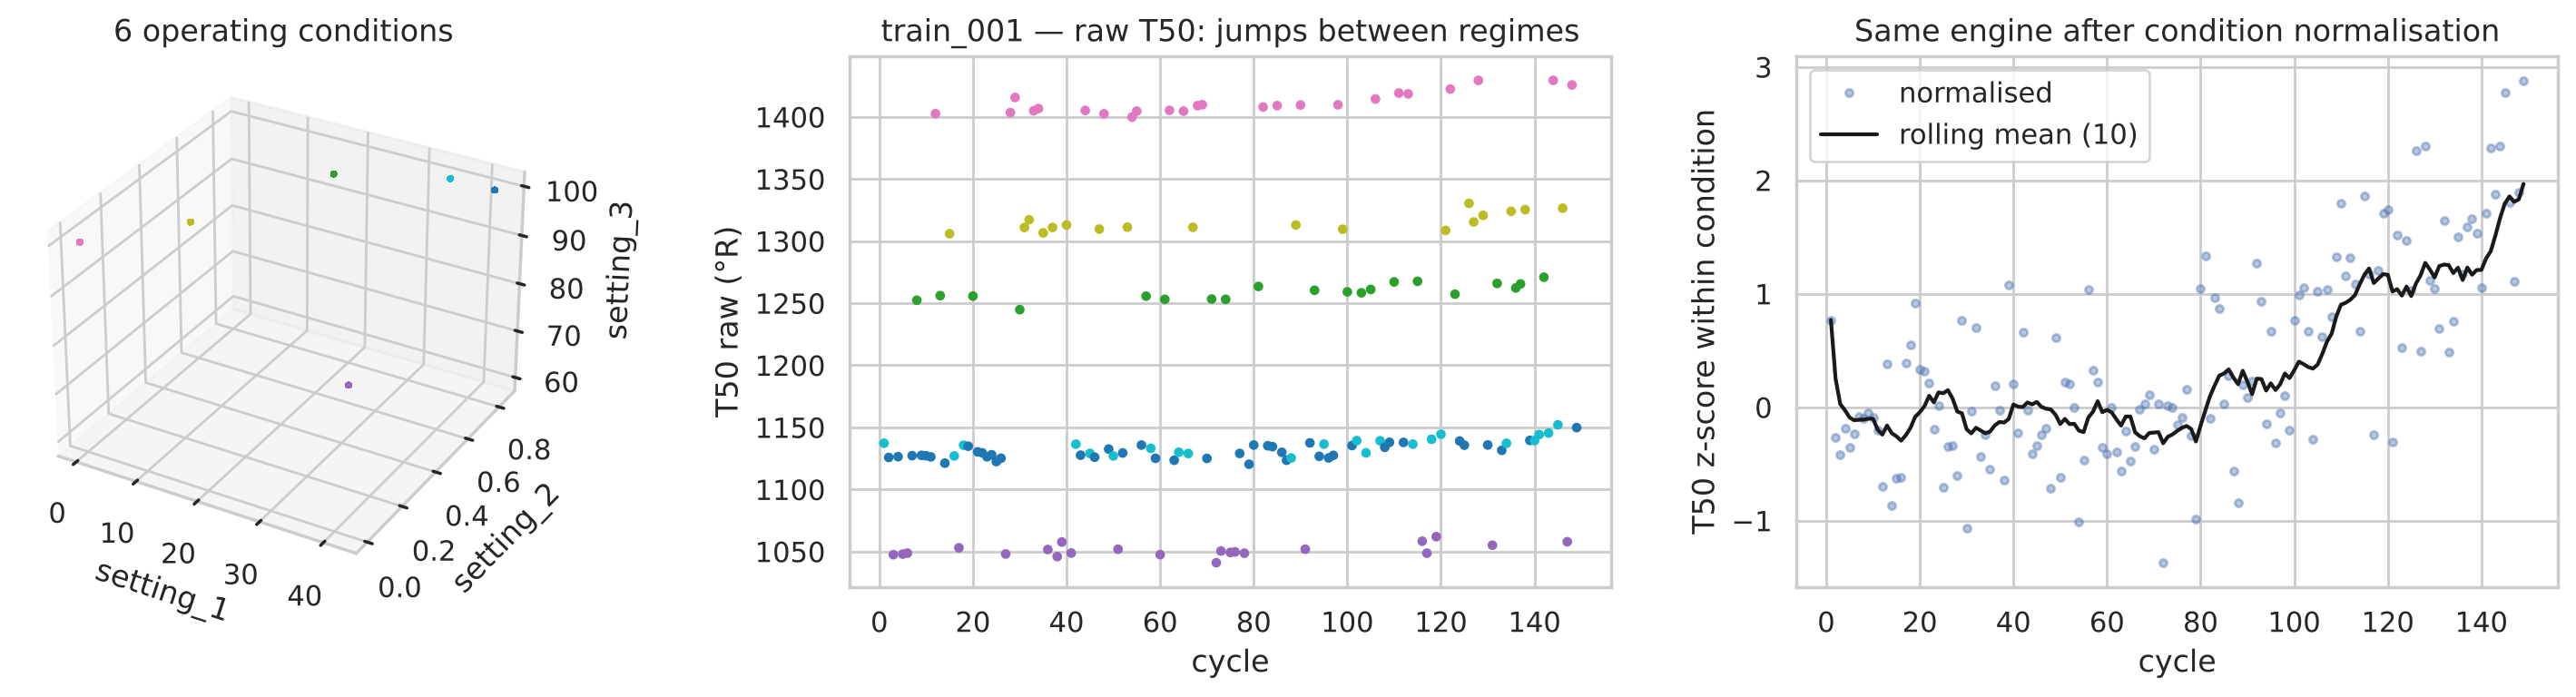

In [9]:
fig = plt.figure(figsize=(15, 4))
ax = fig.add_subplot(1, 3, 1, projection='3d')
ax.scatter(*[train[s] for s in SETTINGS], c=train['op_condition'], cmap='tab10', s=2)
ax.set(xlabel='setting_1', ylabel='setting_2', zlabel='setting_3', title='6 operating conditions')

eng = train[train['engine_uid'] == 'train_001']
ax2 = fig.add_subplot(1, 3, 2)
ax2.scatter(eng['cycle'], eng['T50'], c=eng['op_condition'], cmap='tab10', s=8)
ax2.set(xlabel='cycle', ylabel='T50 raw (°R)', title='train_001 — raw T50: jumps between regimes')
ax3 = fig.add_subplot(1, 3, 3)
z = norm_all.transform(eng)
ax3.plot(eng['cycle'], z['T50'], '.', alpha=.4, label='normalised')
ax3.plot(eng['cycle'], z['T50'].rolling(10, min_periods=1).mean(), 'k', label='rolling mean (10)')
ax3.set(xlabel='cycle', ylabel='T50 z-score within condition', title='Same engine after condition normalisation'); ax3.legend()
plt.tight_layout(); plt.show()

Raw sensor values are dominated by the flight regime (altitude/Mach/throttle). After z-scoring each sensor **within its operating condition**,
the upward drift caused by HPC degradation becomes visible. This is why the baseline normalises per condition.

### 3.2 Which sensors carry information?
The Week-1 specification proposed to drop the 7 sensors with near-zero variance. On FD002 the global variance is misleading (the regime changes
every sensor), so we measure variability **inside each operating condition**.

In [10]:
cond = train['op_condition']
info = pd.DataFrame({
    'max distinct values in a condition': train.groupby(cond)[SENSORS].nunique().max(),
    'mean within-condition std': train.groupby(cond)[SENSORS].std().mean(),
})
z_train = norm_all.transform(train)
with np.errstate(divide='ignore', invalid='ignore'):   # constant sensors give NaN correlation
    info['corr with RUL (normalised)'] = z_train.corrwith(train['RUL'])
info['category'] = np.where(info.index.isin(CONSTANT_SENSORS), 'constant -> drop',
                    np.where(info.index.isin(QUANTISED_SENSORS), 'quantised (2-3 values)', 'continuous -> keep'))
info.round(4).sort_values('max distinct values in a condition')

,max distinct values in a condition,mean within-condition std,corr with RUL (normalised),category
T2,1,0.0000,NaN,constant -> drop
P2,1,0.0000,0.0057,constant -> drop
PCNfR_dmd,1,0.0000,NaN,constant -> drop
Nf_dmd,1,0.0000,NaN,constant -> drop
farB,2,0.0007,-0.2155,quantised (2-3 values)
epr,2,0.0015,0.0408,quantised (2-3 values)
P15,3,0.0036,-0.3364,quantised (2-3 values)
htBleed,12,1.4304,-0.5793,continuous -> keep
W31,110,0.1316,0.4375,continuous -> keep
Ps30,151,0.2386,-0.6936,continuous -> keep


In [11]:
# Quantised sensors: is the flicker between two rounded values related to degradation?
c20 = train[train['op_condition'] == train.loc[train['setting_1'].round() == 20, 'op_condition'].mode()[0]]
bins = pd.cut(c20['RUL'], [-1, 25, 50, 100, 150, 400])
(c20.assign(farB_high=(c20['farB'] == 0.03)).groupby(bins, observed=True)['farB_high'].mean()
    .rename('share of farB = 0.03 (condition altitude 20 kft)').to_frame().round(3))

,share of farB = 0.03 (condition altitude 20 kft)
RUL,
"(-1, 25]",0.899
"(25, 50]",0.477
"(50, 100]",0.117
"(100, 150]",0.030
"(150, 400]",0.023


**Decision.**
* `T2`, `P2`, `Nf_dmd`, `PCNfR_dmd` are **exactly constant** inside each operating condition: they only encode the regime, which the settings already give → **dropped**.
* `P15`, `epr`, `farB` are not constant, but are **quantised** (stored with 2 decimals → 2–3 distinct values per condition). They are not pure noise:
  e.g. `farB` switches from 0.02 to 0.03 near failure in one regime. Dropping them (as planned in Week 1) or keeping them is therefore an
  **empirical question** → we compare both options in cross-validation (Section 6) instead of deciding a priori.
* The remaining 14 sensors are continuous and correlated with RUL after normalisation.

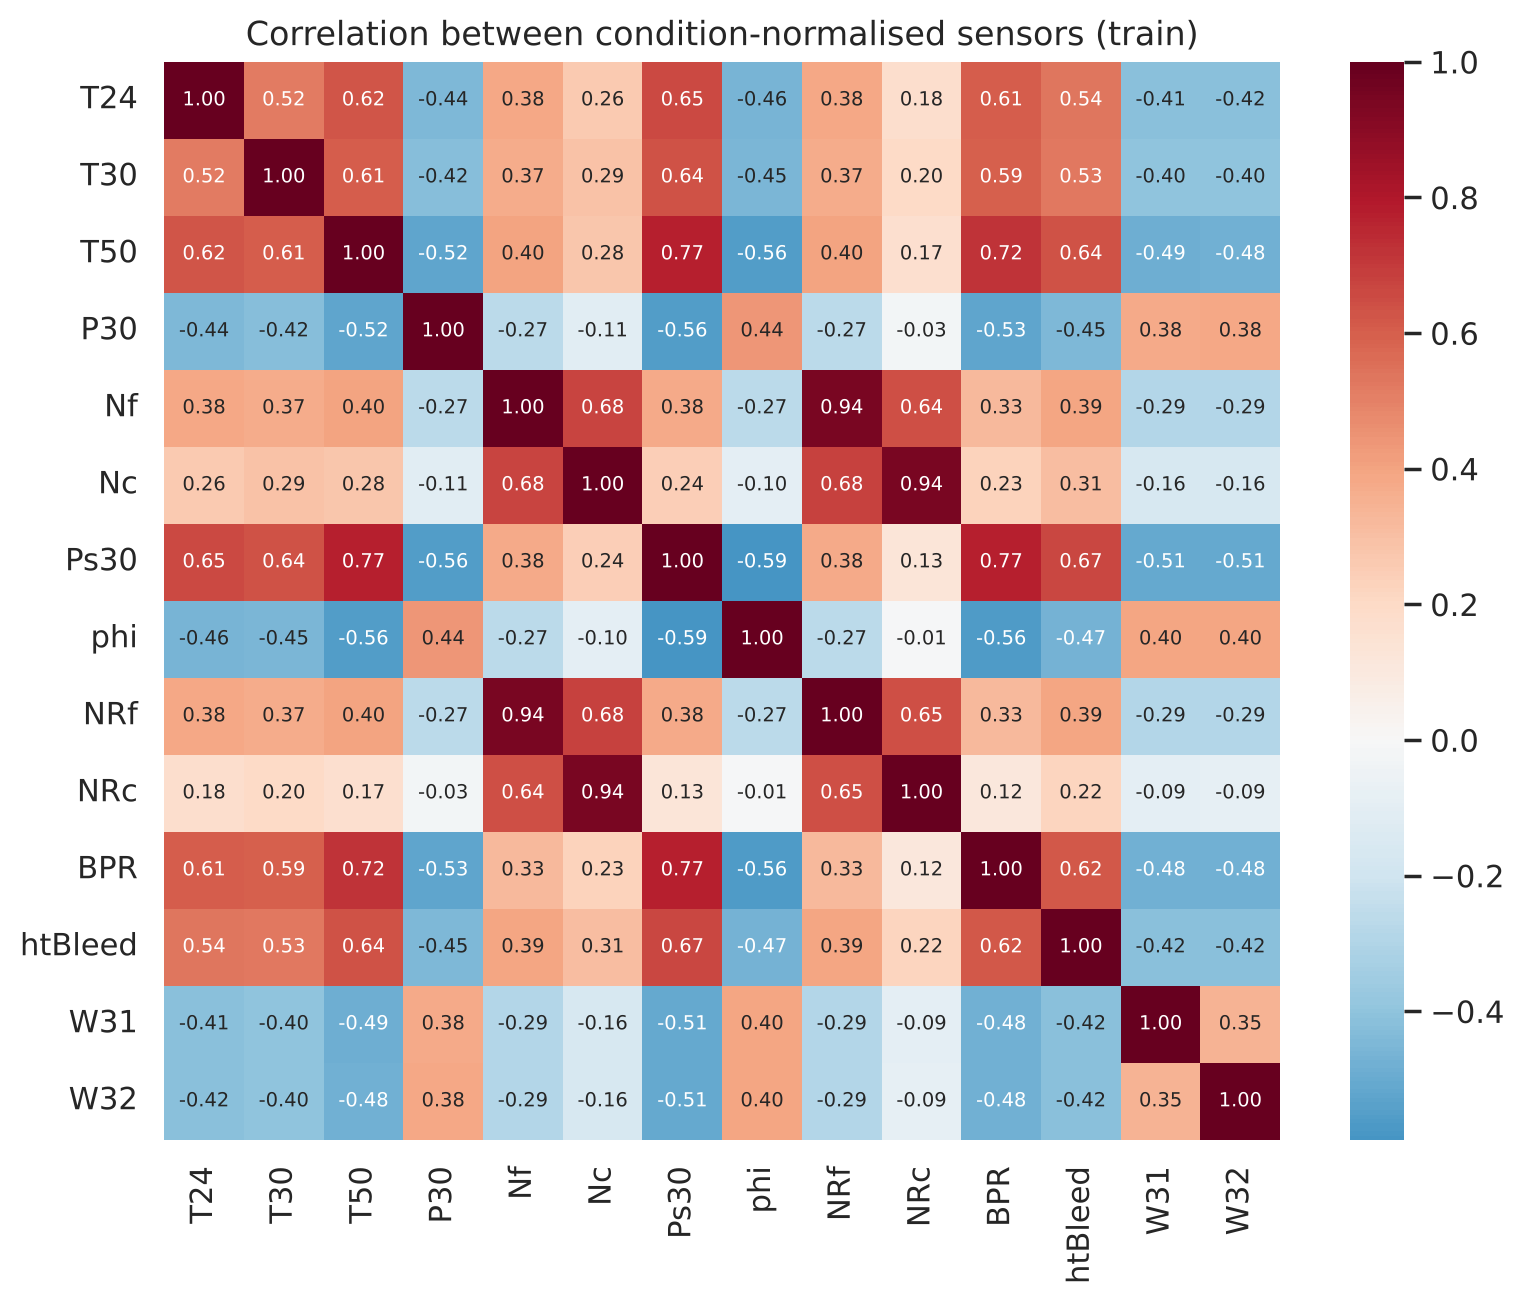

In [12]:
KEEP_14 = [s for s in SENSORS if s not in CONSTANT_SENSORS + QUANTISED_SENSORS]
KEEP_17 = [s for s in SENSORS if s not in CONSTANT_SENSORS]
plt.figure(figsize=(9, 7))
sns.heatmap(z_train[KEEP_14].corr(), cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation between condition-normalised sensors (train)'); plt.show()

Several sensors are strongly correlated (e.g. `T50`, `Ps30`, `BPR`, ...: they all respond to HPC wear). This **multicollinearity** makes ordinary
least squares coefficients unstable, which justifies an L2-regularised linear model (**Ridge**) as baseline.

### 3.3 Target: RUL distribution and capping

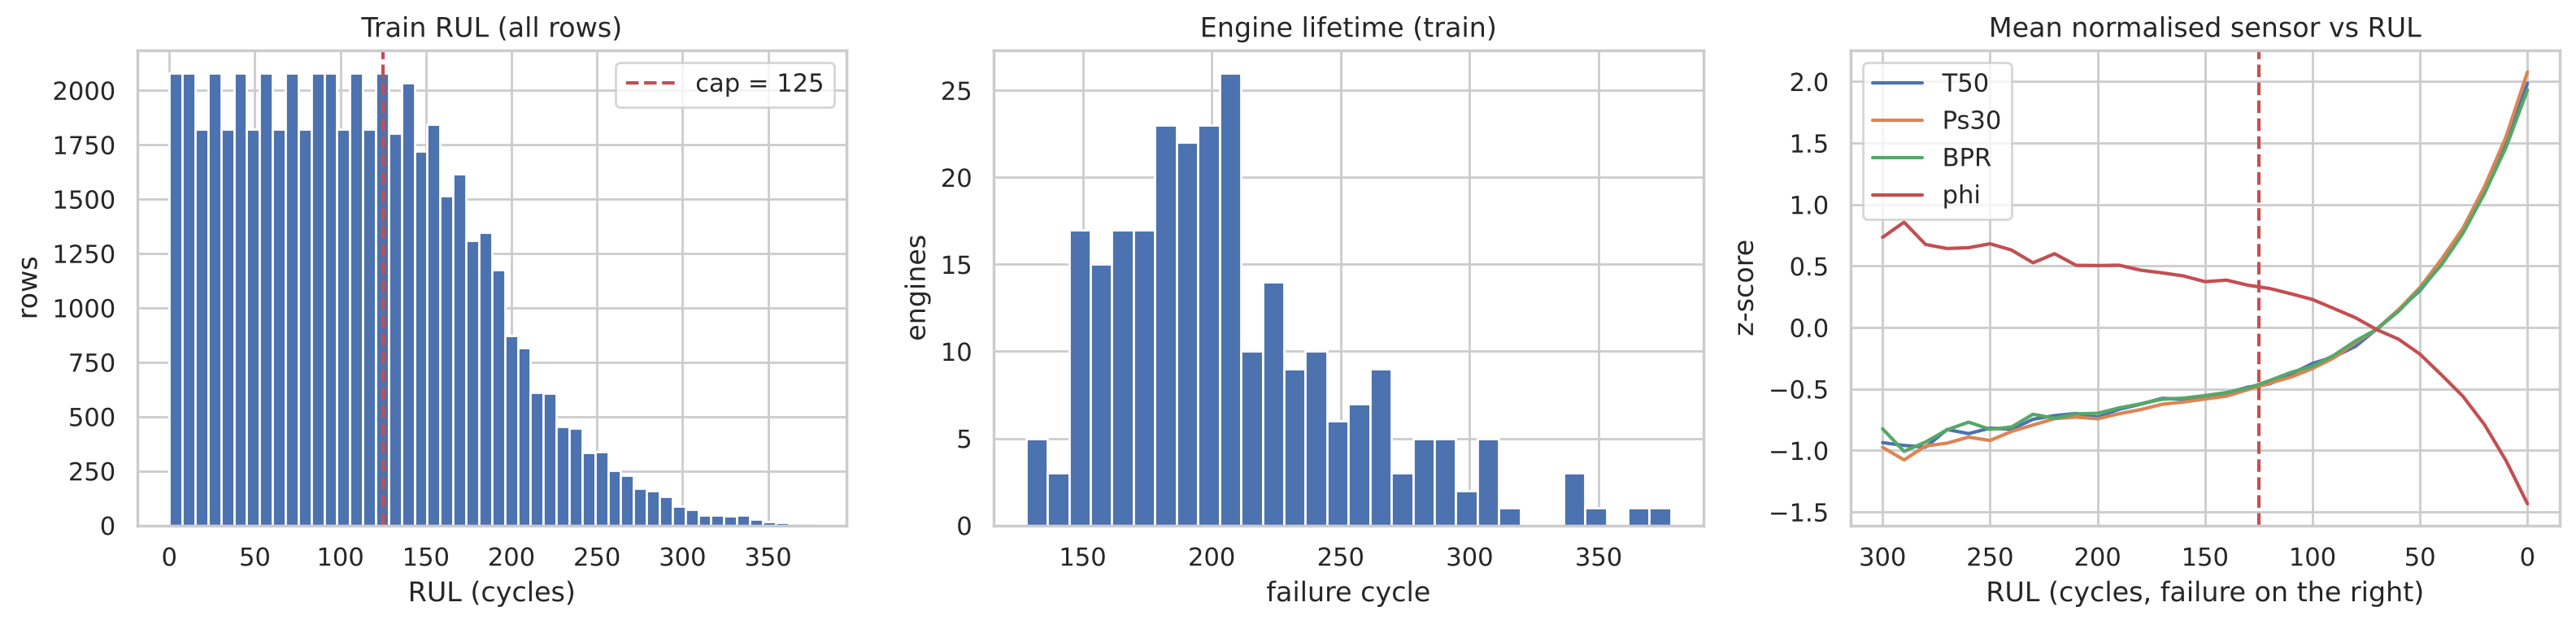

Skewness of RUL: 0.5 | share of rows with RUL > cap: 0.391


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(train['RUL'], bins=50); ax[0].axvline(RUL_CAP, color='r', ls='--', label=f'cap = {RUL_CAP}')
ax[0].set(title='Train RUL (all rows)', xlabel='RUL (cycles)', ylabel='rows'); ax[0].legend()
ax[1].hist(life_tr, bins=30); ax[1].set(title='Engine lifetime (train)', xlabel='failure cycle', ylabel='engines')

binned = z_train[['T50', 'Ps30', 'BPR', 'phi']].groupby((train['RUL'] // 10) * 10).mean()
binned = binned[binned.index <= 300]
for c in binned: ax[2].plot(binned.index, binned[c], label=c)
ax[2].axvline(RUL_CAP, color='r', ls='--'); ax[2].invert_xaxis(); ax[2].legend()
ax[2].set(title='Mean normalised sensor vs RUL', xlabel='RUL (cycles, failure on the right)', ylabel='z-score')
plt.tight_layout(); plt.show()
print('Skewness of RUL:', round(train['RUL'].skew(), 2), '| share of rows with RUL > cap:', round((train['RUL'] > RUL_CAP).mean(), 3))

* The raw RUL is right-skewed (long-lived engines) and runs up to 377 cycles.
* The sensors drift only **slowly** while the engine is healthy (≈ 0.3 std between RUL = 300 and RUL = 150) and accelerate sharply in the
  last ~100 cycles (right panel). Between RUL = 300 and RUL = 200 the change is small compared to the noise of a single cycle (std = 1),
  so a model cannot reliably distinguish these RUL values.
* We therefore train on a **piecewise-linear target** `RUL_capped = min(RUL, 125)`, the standard choice for C-MAPSS (Heimes, 2008; Li et al., 2018).
  Capping only transforms the label of each row independently, so it does not leak information across sets.
* "Imbalance" in a regression sense: after capping, ~40 % of rows sit at 125; this is acceptable for a baseline but will be monitored in Week 3.

### 3.4 Outliers

In [14]:
z14 = z_train[KEEP_14]
print('Share of values with |z| > 4 (within condition):', round((z14.abs() > 4).to_numpy().mean() * 100, 3), '%')
late = train['RUL'] <= 25
print('  ... among rows with RUL <= 25 :', round((z14[late].abs() > 4).to_numpy().mean() * 100, 3), '%')
print('  ... among rows with RUL > 25  :', round((z14[~late].abs() > 4).to_numpy().mean() * 100, 3), '%')

Share of values with |z| > 4 (within condition): 0.251 %
  ... among rows with RUL <= 25 : 1.924 %
  ... among rows with RUL > 25  : 0.01 %


Extreme values are concentrated near failure: they are the **degradation signal**, not measurement errors. We **do not remove outliers**;
removing them would delete the most informative cycles.

## 4. Clean dataset (exported)
The clean files keep raw (un-normalised) values. Normalisation statistics are **not** baked in: they are learned inside the model pipeline
on each training fold (Section 5), otherwise validation scores would be optimistic.

In [15]:
clean_cols = ['engine_uid', 'unit_id', 'cycle', 'op_condition'] + SETTINGS + KEEP_17 + ['RUL']
train_clean = train[clean_cols].assign(RUL_capped=train['RUL'].clip(upper=RUL_CAP))
test_clean = test[clean_cols].assign(RUL_capped=test['RUL'].clip(upper=RUL_CAP))
train_clean.to_csv(DATA_PROCESSED / 'train_clean.csv', index=False)
test_clean.to_csv(DATA_PROCESSED / 'test_clean.csv', index=False)
print(train_clean.shape, test_clean.shape)
train_clean.head(3)

(53759, 26) (33991, 26)


,engine_uid,unit_id,cycle,op_condition,setting_1,setting_2,setting_3,T24,T30,T50,P15,P30,Nf,Nc,epr,Ps30,phi,NRf,NRc,BPR,farB,htBleed,W31,W32,RUL,RUL_capped
0,train_001,1,1,5,34.9983,0.8400,100.0,555.32,1358.61,1137.23,8.00,194.64,2222.65,8341.91,1.02,42.02,183.06,2387.72,8048.56,9.3461,0.02,334,14.73,8.8071,148,125
1,train_001,1,2,0,41.9982,0.8408,100.0,549.90,1353.22,1125.78,5.71,138.51,2211.57,8303.96,1.02,42.20,130.42,2387.66,8072.30,9.3774,0.02,330,10.41,6.2665,147,125
2,train_001,1,3,2,24.9988,0.6218,60.0,537.31,1256.76,1047.45,9.02,175.71,1915.11,8001.42,0.94,36.69,164.22,2028.03,7864.87,10.8941,0.02,309,14.08,8.6723,146,125


## 5. Learning and evaluation plan (train / validation / test)

| Set | Content | Use |
|---|---|---|
| **Train** | 260 run-to-failure engines | model fitting, via 5-fold **GroupKFold** grouped by `engine_uid` |
| **Validation** | the held-out engines of each fold (~52 engines) | model selection (alpha, sensor set), never seen by the preprocessing of that fold |
| **Test** | 259 truncated engines (NASA) | **one final evaluation**, last cycle of each engine, after all choices are frozen |

Rules applied to avoid leakage:
1. Folds are built by engine: all cycles of an engine are in the same fold (checked below).
2. KMeans and per-condition mean/std are inside the `Pipeline` → re-fitted on each training fold only.
3. The test set is not used for any choice. Its `RUL` column is only used to compute final metrics.

Metrics (on validation folds):
* **all rows** — RMSE / MAE against capped RUL, every cycle of every validation engine;
* **random cut** — one random cycle per validation engine, which reproduces how the test set was built; this is the score that
  best predicts the test score. NASA score is reported on this one-prediction-per-engine protocol (it is a sum over engines).

In [16]:
X, y = train_clean, train_clean['RUL_capped']
groups = train_clean['engine_uid']
gkf = GroupKFold(n_splits=5)
folds = list(gkf.split(X, y, groups))
for k, (tr_idx, va_idx) in enumerate(folds):
    assert not set(groups.iloc[tr_idx]) & set(groups.iloc[va_idx]), 'engine in both train and validation!'
    print(f'fold {k}: {groups.iloc[tr_idx].nunique()} train engines, {groups.iloc[va_idx].nunique()} validation engines')

fold 0: 208 train engines, 52 validation engines
fold 1: 208 train engines, 52 validation engines
fold 2: 208 train engines, 52 validation engines
fold 3: 208 train engines, 52 validation engines
fold 4: 208 train engines, 52 validation engines


## 6. Baseline models
We compare, under the same protocol:

| Model | Features | Why |
|---|---|---|
| `Mean` | none (predicts mean capped RUL) | floor: any useful model must beat it |
| `Ridge raw` | settings + 14 raw sensors, standard-scaled | shows the effect of *not* handling operating conditions |
| `Ridge cond-norm 14` | 14 sensors z-scored per condition | **planned baseline** (Week-1 spec) |
| `Ridge cond-norm 17` | + quantised `P15`, `epr`, `farB` | tests the sensor-selection decision of Section 3.2 |

All models use only the **current cycle** (no time window): history features are the Week-3 improvement.

In [17]:
def make_models(alpha=1.0):
    return {
        'Mean': DummyRegressor(strategy='mean'),
        'Ridge raw': Pipeline([
            ('select', ColumnTransformer([('keep', 'passthrough', SETTINGS + KEEP_14)])),
            ('scale', StandardScaler()),
            ('ridge', Ridge(alpha=alpha))]),
        'Ridge cond-norm 14': Pipeline([
            ('norm', ConditionNormalizer(sensors=KEEP_14)),
            ('ridge', Ridge(alpha=alpha))]),
        'Ridge cond-norm 17': Pipeline([
            ('norm', ConditionNormalizer(sensors=KEEP_17)),
            ('ridge', Ridge(alpha=alpha))]),
    }

def cross_validate_model(model, X, y, folds, seed=RANDOM_STATE):
    rows = []
    for k, (tr_idx, va_idx) in enumerate(folds):
        m = clone(model).fit(X.iloc[tr_idx], y.iloc[tr_idx])          # preprocessing re-fitted on the fold
        va = X.iloc[va_idx]
        all_rows = regression_report(y.iloc[va_idx], np.clip(m.predict(va), 0, None))
        cut = random_truncation(va, seed=seed + k)
        one = regression_report(cut['RUL_capped'], np.clip(m.predict(cut), 0, None))
        rows.append({'fold': k, 'RMSE all rows': all_rows['RMSE'], 'MAE all rows': all_rows['MAE'],
                     'RMSE random cut': one['RMSE'], 'MAE random cut': one['MAE'],
                     'NASA score / engine (random cut)': one['NASA score'] / one['n']})
    return pd.DataFrame(rows)

cv = {name: cross_validate_model(m, X, y, folds) for name, m in make_models().items()}
cv_mean = pd.DataFrame({n: r.drop(columns='fold').mean() for n, r in cv.items()}).T
cv_std = pd.DataFrame({n: r.drop(columns='fold').std() for n, r in cv.items()}).T
cv_mean.round(2).astype(str) + ' ± ' + cv_std.round(2).astype(str)

,RMSE all rows,MAE all rows,RMSE random cut,MAE random cut,NASA score / engine (random cut)
Mean,41.67 ± 0.0,36.95 ± 0.0,43.03 ± 3.2,37.51 ± 2.88,378.53 ± 203.35
Ridge raw,22.2 ± 0.52,17.87 ± 0.44,22.99 ± 2.28,18.64 ± 2.49,14.72 ± 3.09
Ridge cond-norm 14,21.65 ± 0.59,17.37 ± 0.53,23.05 ± 2.29,18.77 ± 2.48,16.39 ± 7.04
Ridge cond-norm 17,21.62 ± 0.6,17.34 ± 0.53,23.11 ± 2.16,18.77 ± 2.47,16.48 ± 6.84


### 6.1 Ridge regularisation strength
Ridge has a single hyperparameter, `alpha`. Since the condition-normalised features are already on a common scale and there are many more
rows (~43 000 per fold) than features (14–17), we expect alpha to matter little; we check it on the validation folds.

In [18]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]
alpha_scan = pd.DataFrame({
    a: cross_validate_model(make_models(alpha=a)['Ridge cond-norm 14'], X, y, folds)[['RMSE all rows', 'RMSE random cut']].mean()
    for a in alphas}).T.rename_axis('alpha')
alpha_scan.round(3)

,RMSE all rows,RMSE random cut
alpha,,
0.01,21.654,23.046
0.10,21.654,23.046
1.00,21.654,23.046
10.00,21.654,23.046
100.00,21.655,23.049
1000.00,21.667,23.089


**Reading the CV table.**
* Every Ridge model is far better than the mean predictor (RMSE ≈ 23 vs 43 cycles on the random-cut protocol).
* **Surprise:** `Ridge raw` is as good as the condition-normalised Ridge (differences ≈ 0.1 cycle, much smaller than the fold-to-fold std ≈ 2.3).
  A linear model can partly cancel the regime effect by combining several raw sensors with the settings, because in FD002 the regime shifts
  all sensors together. So, for a *single-cycle linear* model, per-condition normalisation is **not** what drives performance.
* Keeping the quantised sensors (`P15`, `epr`, `farB`) changes nothing measurable → we keep the simpler 14-sensor set.
* `alpha` has no effect between 0.01 and 100 (flat curve), as expected with ~43 000 rows for 14 features → we keep the default `alpha = 1`.

**Selected baseline: `Ridge cond-norm 14`, alpha = 1.** Its score is statistically tied with `Ridge raw`; we prefer it because
(i) its coefficients are interpretable (one coefficient = effect of one standard deviation of degradation of a sensor) and
(ii) the Week-3 features (rolling mean / slope over 30 cycles) only make sense on condition-normalised signals: on raw sensors the window would
mix 6 different regimes. We will keep `Ridge raw` in the comparison table as a second reference.

Per-fold RMSE difference (raw − cond-norm): [-0.49, 0.7, -0.35, -0.71, 0.59]


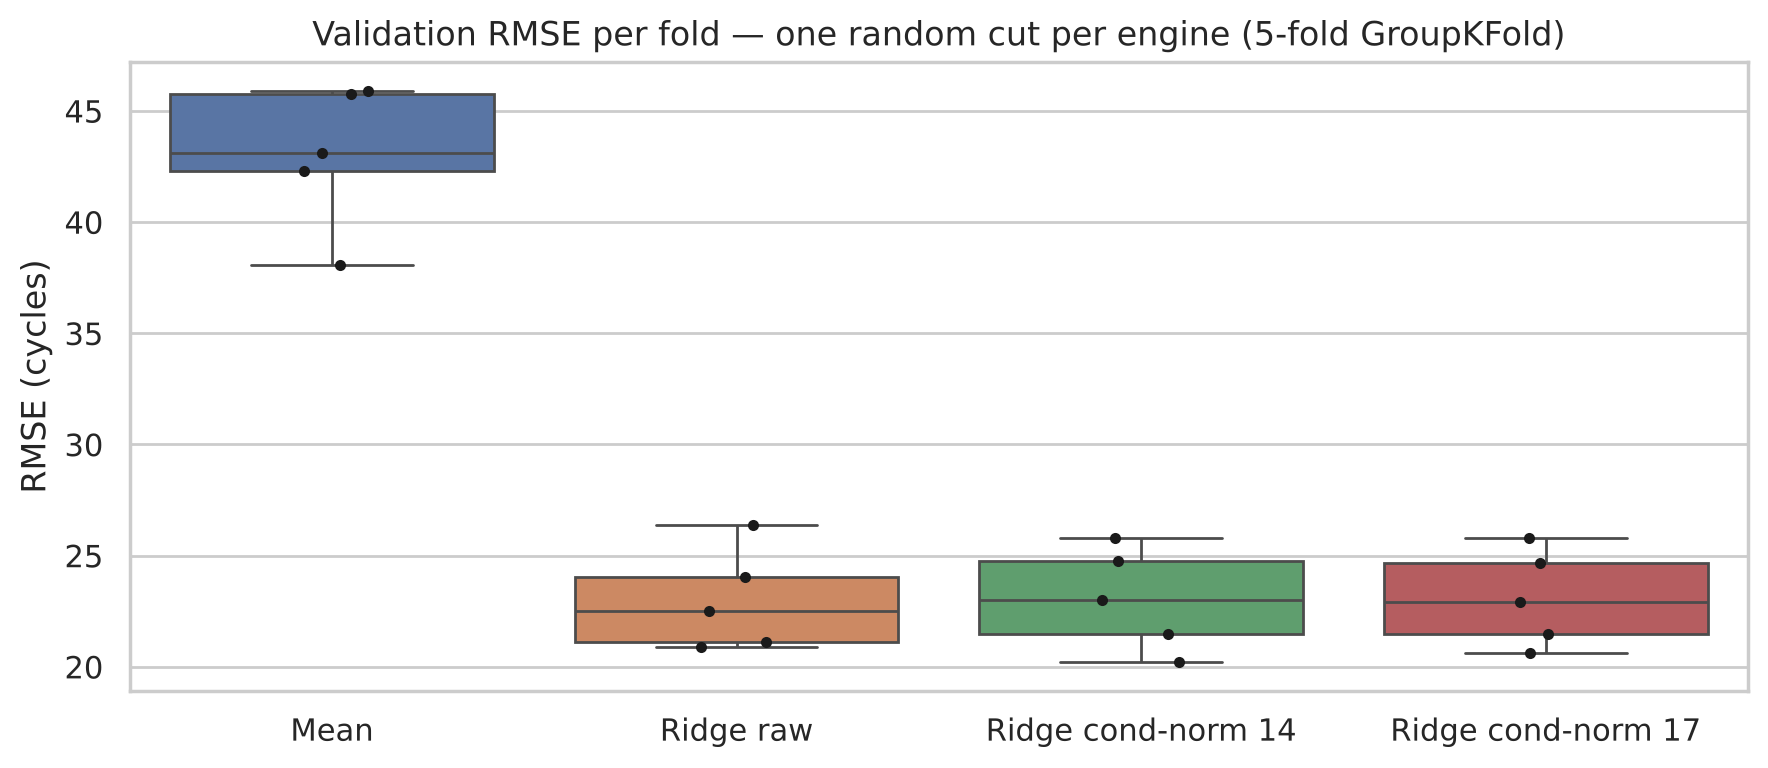

In [19]:
best_name, best_alpha = 'Ridge cond-norm 14', 1.0
paired = cv['Ridge raw']['RMSE random cut'] - cv[best_name]['RMSE random cut']
print('Per-fold RMSE difference (raw − cond-norm):', paired.round(2).tolist())

fig, ax = plt.subplots(figsize=(9, 4))
plot_df = pd.concat({n: r['RMSE random cut'] for n, r in cv.items()}, axis=1)
sns.boxplot(data=plot_df, ax=ax); sns.stripplot(data=plot_df, ax=ax, color='k', size=4)
ax.set(ylabel='RMSE (cycles)', title='Validation RMSE per fold — one random cut per engine (5-fold GroupKFold)')
plt.tight_layout(); plt.show()

## 7. Final evaluation on the NASA test set (run once)
The selected pipeline is re-fitted on the **whole train set** and evaluated on the last observed cycle of each of the 259 test engines.
We report the score against the true RUL and against the capped RUL (the convention used by most C-MAPSS papers, since the model cannot
predict beyond the cap by construction).

In [20]:
final = clone(make_models(alpha=best_alpha)[best_name]).fit(X, y)
mean_model = DummyRegressor().fit(X, y)

test_last = last_cycle(test_clean)
results = {}
raw_ref = clone(make_models(alpha=best_alpha)['Ridge raw']).fit(X, y)
for name, model in [('Mean', mean_model), ('Ridge raw', raw_ref), (best_name, final)]:
    pred_last = np.clip(model.predict(test_last), 0, None)
    pred_all = np.clip(model.predict(test_clean), 0, None)
    results[(name, 'last cycle, true RUL')] = regression_report(test_last['RUL'], pred_last)
    results[(name, 'last cycle, capped RUL')] = regression_report(test_last['RUL_capped'], pred_last)
    results[(name, 'all rows, capped RUL')] = regression_report(test_clean['RUL_capped'], pred_all)
test_results = pd.DataFrame(results).T
test_results.round(2)

RMSE    MAE  NASA score        n
Mean               last cycle, true RUL    54.08  45.64   153229.26    259.0
                   last cycle, capped RUL  44.93  38.14   115589.85    259.0
                   all rows, capped RUL    35.57  33.22  1596119.57  33991.0
Ridge raw          last cycle, true RUL    32.40  23.91    19889.31    259.0
                   last cycle, capped RUL  21.01  17.12     2766.43    259.0
                   all rows, capped RUL    22.53  18.30   353511.74  33991.0
Ridge cond-norm 14 last cycle, true RUL    32.35  23.82    18277.74    259.0
                   last cycle, capped RUL  20.91  16.96     2873.45    259.0
                   all rows, capped RUL    22.14  17.96   336579.47  33991.0

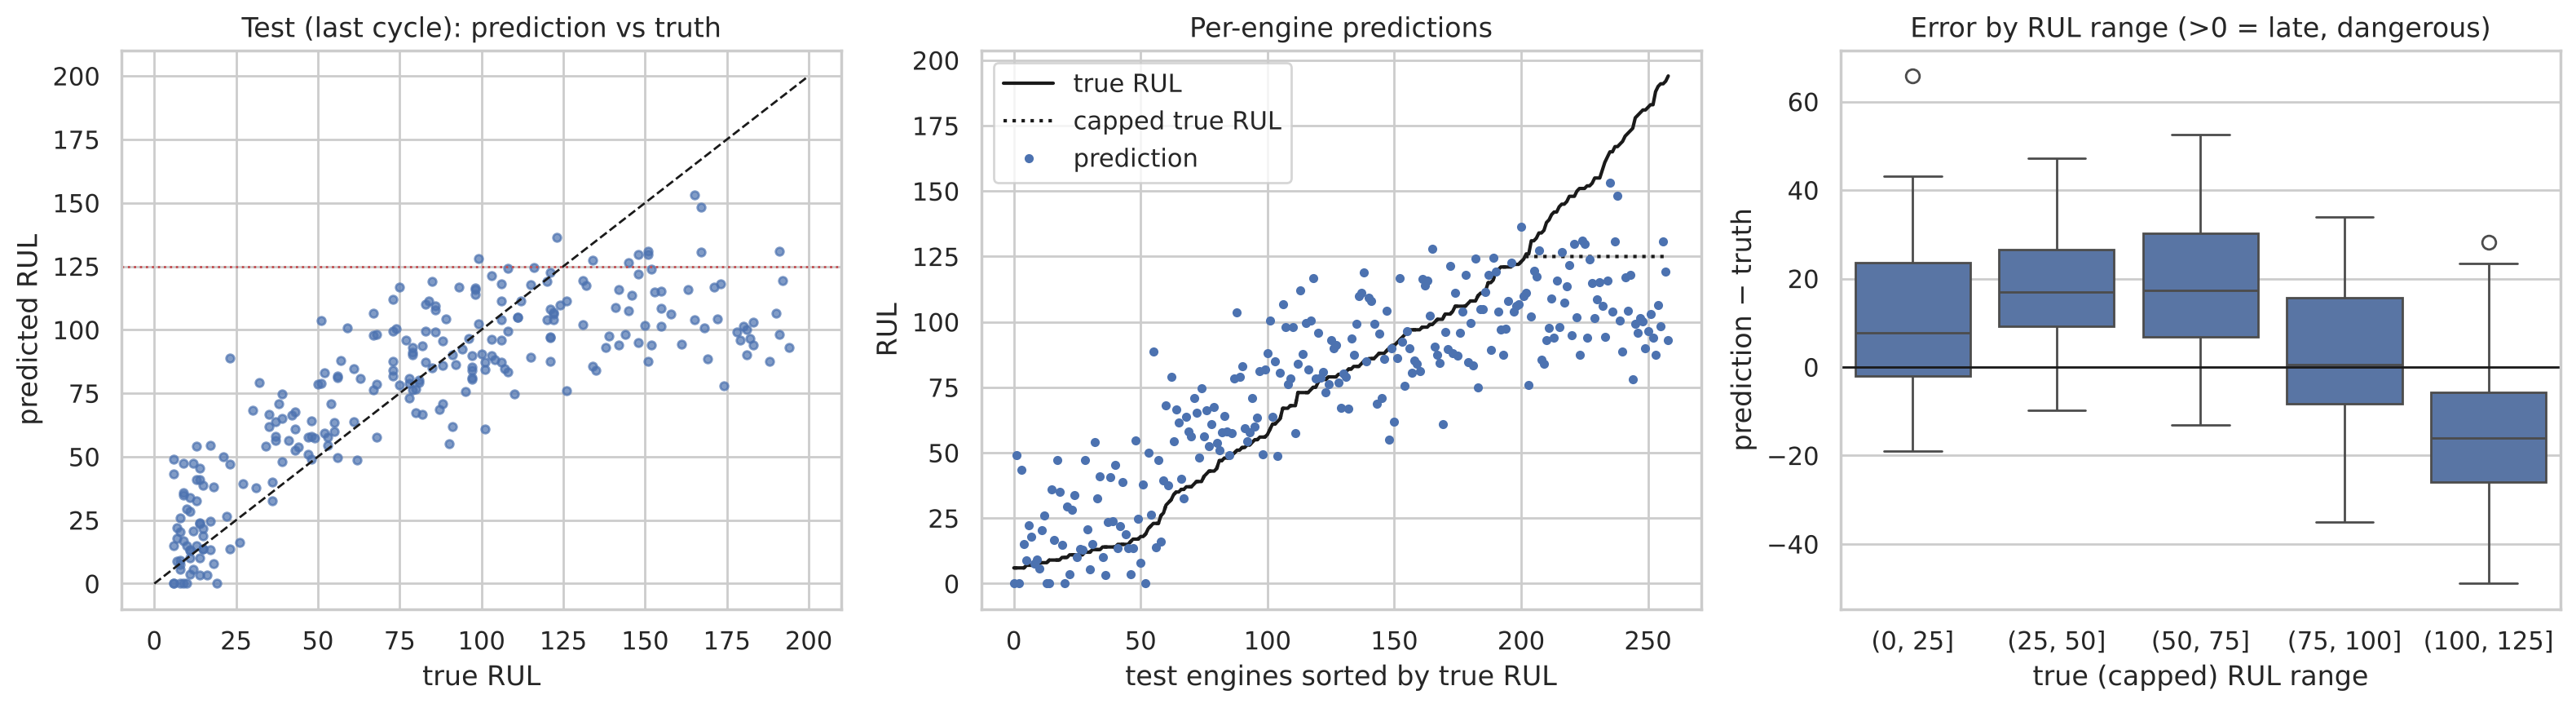

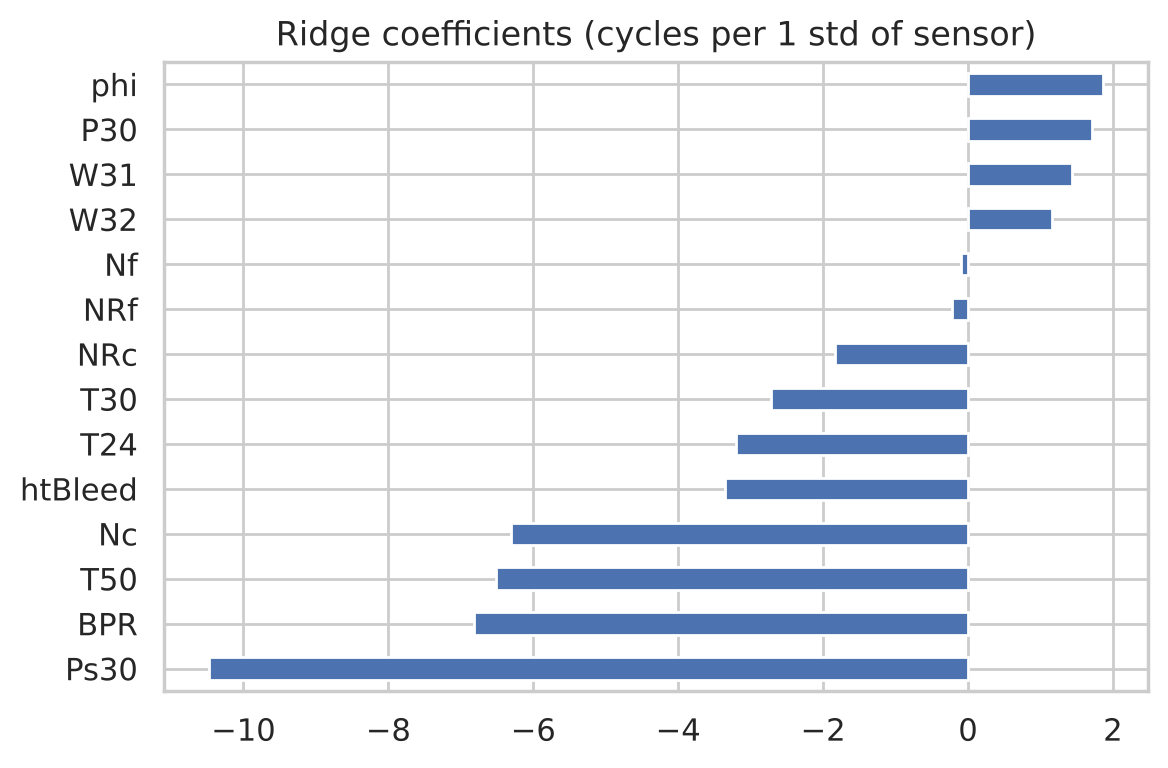

In [21]:
pred = np.clip(final.predict(test_last), 0, None)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(test_last['RUL'], pred, s=12, alpha=.7)
ax[0].plot([0, 200], [0, 200], 'k--', lw=1); ax[0].axhline(RUL_CAP, color='r', ls=':', lw=1)
ax[0].set(xlabel='true RUL', ylabel='predicted RUL', title='Test (last cycle): prediction vs truth')

order = np.argsort(test_last['RUL'].to_numpy())
ax[1].plot(test_last['RUL'].to_numpy()[order], 'k', label='true RUL')
ax[1].plot(test_last['RUL_capped'].to_numpy()[order], 'k:', label='capped true RUL')
ax[1].plot(pred[order], '.', label='prediction'); ax[1].legend()
ax[1].set(xlabel='test engines sorted by true RUL', ylabel='RUL', title='Per-engine predictions')

err = pred - test_last['RUL_capped'].to_numpy()
bins = pd.cut(test_last['RUL_capped'], [0, 25, 50, 75, 100, 125])
sns.boxplot(x=bins, y=err, ax=ax[2]); ax[2].axhline(0, color='k', lw=1)
ax[2].set(xlabel='true (capped) RUL range', ylabel='prediction − truth', title='Error by RUL range (>0 = late, dangerous)')
plt.tight_layout(); plt.show()

coefs = pd.Series(final.named_steps['ridge'].coef_, index=final.named_steps['norm'].sensors_).sort_values()
coefs.plot.barh(figsize=(6, 4), title='Ridge coefficients (cycles per 1 std of sensor)'); plt.tight_layout(); plt.show()

## 8. Summary and next steps

**Data preparation**
* Data are clean (no missing value, no duplicate, no gap). Preprocessing = (1) drop 4 sensors that are constant within each regime,
  (2) cluster the 3 settings into 6 operating conditions with KMeans, (3) z-score each sensor within its condition, (4) cap RUL at 125.
  Steps (2)–(3) are learned inside the pipeline on training folds only.
* The provided split is the official NASA split, made **by engine**: no shared engine, no shared rows, same operating-condition mix and
  same healthy-state sensor distribution in train and test. Test engines are truncated, so the test is evaluated on their last cycle.

**Baseline** — Ridge on 14 condition-normalised sensors, current cycle only, target capped at 125.
* Cross-validation (5-fold GroupKFold, one random cut per engine): RMSE ≈ 23 cycles vs ≈ 43 for the mean predictor.
* NASA test set (259 engines, last cycle): see the table in Section 7 — RMSE ≈ 21 cycles against the capped RUL, ≈ 32 against the true RUL.
  The CV estimate (≈ 23) is consistent with the test score, which confirms that the random-cut validation protocol reproduces the test situation.
* Ridge on raw sensors performs the same: condition normalisation is not useful for a single-cycle linear model, but it is required for the
  Week-3 window features. This RMSE is the reference to beat in Week 3.

**Known limitations of the baseline (to address in Week 3)**
1. It uses one cycle only → noisy predictions; add rolling-window features (mean, slope over the last 30 cycles), as planned.
2. It is linear while degradation is non-linear (exponential at the end) → tree ensembles / neural networks.
3. Test engines with a long true RUL (> 125) are capped by construction; report both conventions and discuss.
4. Typical regression-to-the-mean pattern (error plot): the model **over-estimates short RULs** (median error ≈ +10 to +17 cycles for RUL < 75,
  i.e. late predictions, the dangerous ones for maintenance) and under-estimates RULs close to the cap.
5. When Week-3 models get real hyperparameters, choose them with nested CV (or an inner GroupKFold) so the reported CV score stays unbiased.